# L8 — When is it safe to spread fertiliser? Choosing the rain data behind the *jendela tabur*

*Krops weather notebooks · 2 of 2 · [1 — L5 water stress](01_L5_water_stress.ipynb) · design: [Krops L5 & L8 — Weather Data Design](https://claude.ai/code/artifact/1c498342-d6cd-48a9-bd7f-7da06669b02a)*

## Problem statement

L8 tells the farmer when to spread fertiliser. Fertiliser spread just before a downpour can be washed off or leached past the roots; in a dry month it sits on the surface unused. Smallholders spread two or three times a year, so each mistimed round is lost money and a weaker palm.

The proposal (17 Sep 2026), following Pradiko & Koedadiri (2015) and Goh et al., sets the rules: spread in months with **100–200 mm** of rain, avoid months under **60 mm** or over **300 mm**, and avoid any day with more than **25 mm**. On 9 Oct we added: 60–100 mm → *cek*; 200–300 mm → open; also skip **the day before** each heavy day (a team rule, no source yet); and build both a **10-year and a 30-year** month table and compare them.

The rules are monthly and daily, but WeatherKit, our forecast source for the iPhone MVP, has no monthly forecast. So L8 became two stages: **Stage A**, a month gate from long-term rain history, and **Stage B**, a day pick from the 10-day forecast.

**The problem:** which rain data can tell a farmer which of the next 10 days are safe to spread on? The end result is the full L8 output for the Tanjung Pinang plot today: **Tunda / Cek / Jendela tabur / Cek hujan**, and how far to trust it.

## Thinking flow

1. Which providers could feed L8?
2. What can each provider actually forecast here?
3. Stage A: what do the month tables say, and does 10 vs 30 years matter?
4. Stage B: which days does today's forecast leave?
5. What do the extra rules cost?
6. Do the sources agree on heavy days?
7. How good is the forecast 1–3 days ahead?
8. Putting it together: the L8 decision, end to end

### 1. Which providers could feed L8?

The WeatherKit spec sheet (8 Oct) showed a 10-day daily forecast (and hourly up to 240 hours), but no monthly forecast and no climatology over REST. That is why NASA POWER joined for Stage A.

| Provider | What it offers for L8 | Why it stayed or went |
| --- | --- | --- |
| **Apple WeatherKit** | 10-day daily forecast: mm, chance, 07:00–19:00 part | **Chosen for Stage B.** The MVP is an iPhone; 10 days covers a spreading window |
| **NASA POWER** | Daily rain since 1981, free | **Chosen for Stage A** (month table) |
| **BMKG public API** | Village-level forecast, 3-hourly | **Dropped: horizon too short** for a 10-day window. Step 2 measures it |
| **BMKG monthly outlook** | Monthly rain forecast up to 3 months ahead | Iteration 2+: could adjust Stage A in unusually dry or wet years. PDF bulletins only |
| **Open-Meteo** | Forecast up to 16 days; history | Not evaluated at the time (see below) |
| **Rain gauge / BMKG station** | Measured daily rain | Validation only |

**Open-Meteo.** Its [forecast API](https://open-meteo.com/en/docs) reaches **16 days** (7 by default) and blends several national weather models. A longer horizon than WeatherKit's would let L8 plan further ahead. But the [free API is for non-commercial use only](https://open-meteo.com/en/pricing); a paid service like Krops needs a paid plan. Worth pricing if a 10-day window proves too short.

In [1]:
from datetime import date, datetime, timedelta

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import krops_weather as kw
from krops_weather import HEAVY_RAIN_MM, LAT, LON, SITE_NAME, TODAY, TZ, WK_READY

kw.use_chart_style()
print(f"{SITE_NAME}: {LAT}, {LON} · today {TODAY} · WeatherKit credentials: {'yes' if WK_READY else 'no (WeatherKit cells skip)'}")

Tanjung Pinang: 0.92, 104.45 · today 2026-10-11 · WeatherKit credentials: yes


### 2. What can each provider actually forecast here?

**Why we ask.** Apple's data-source page lists no Indonesian agency, so some WeatherKit data sets may not exist in Riau. And we dropped BMKG's API for its short horizon without measuring it.

**WeatherKit.** The availability endpoint lists the data sets at this coordinate. Then the 10-day forecast, with the four columns Stage B logs:

| Column | Meaning |
| --- | --- |
| `rain_mm` | `precipitationAmount`: expected rain over the day (00:00–24:00 WIB), mm. **Stage B uses this** |
| `rain_chance` | `precipitationChance`: probability of any rain, 0–1. Logged, no rule (any threshold would be a guess today) |
| `daytime_rain_mm`, `daytime_rain_chance` | The same for 07:00–19:00, when field work happens |

Amount and chance answer different questions: a 0.65 chance of 2 mm is a likely shower that harms nothing; a 0.3 chance of 30 mm is an unlikely storm that would.

In [2]:
forecast = None
if WK_READY:
    print("WeatherKit data sets here:", kw.wk_availability())
    forecast_raw = kw.fetch_weatherkit_daily()
    print("Forecast read at:", forecast_raw["forecastDaily"].get("metadata", {}).get("readTime"))
    forecast = kw.tidy_weatherkit_days(forecast_raw)
    display(forecast)
else:
    print("Skipped: add WeatherKit credentials to .env")

WeatherKit data sets here: ['currentWeather', 'forecastDaily', 'forecastHourly']
Forecast read at: 2026-10-11T15:01:46Z


,date,rain_mm,rain_chance,daytime_rain_mm,daytime_rain_chance
0,2026-10-11,2.38,0.65,1.83,0.37
1,2026-10-12,2.34,0.53,2.34,0.41
2,2026-10-13,6.38,0.68,6.26,0.60
3,2026-10-14,1.54,0.61,0.90,0.32
4,2026-10-15,12.78,0.65,11.79,0.46
5,2026-10-16,7.96,0.55,6.69,0.37
6,2026-10-17,5.11,0.64,4.49,0.48
7,2026-10-18,1.10,0.51,0.71,0.29
8,2026-10-19,3.03,0.41,1.75,0.25
9,2026-10-20,6.12,0.45,5.97,0.30


**BMKG's public API** gives a forecast for one *kelurahan*, identified by its administrative code (`BMKG_ADM4`, default Tanjung Pinang Barat, the closest to the plot). We sum its 3-hourly rain (`tp`) per day and set it next to WeatherKit for the days both cover.

In [3]:
bmkg_place, bmkg_fc = kw.fetch_bmkg_forecast()
now = datetime.now(TZ).replace(tzinfo=None)
hours_ahead = (bmkg_fc["local_datetime"].max() - now).total_seconds() / 3600
print(f"BMKG forecast for {bmkg_place['desa']}, {bmkg_place['kotkab']} ({float(bmkg_place['lat']):.3f}, {float(bmkg_place['lon']):.3f}): "
      f"{len(bmkg_fc)} steps of 3 h, last at {bmkg_fc['local_datetime'].max():%a %d %b %H:%M} — {hours_ahead:.0f} hours ahead")

bmkg_daily = bmkg_fc.groupby(bmkg_fc["local_datetime"].dt.date).agg(bmkg_rain_mm=("tp", "sum"), bmkg_steps=("tp", "size"))
if forecast is not None:
    side_by_side = forecast.set_index("date")[["rain_mm", "rain_chance"]].rename(columns={"rain_mm": "weatherkit_rain_mm"})
    display(side_by_side.join(bmkg_daily, how="inner"))  # a day is complete in BMKG with 8 steps
else:
    display(bmkg_daily)

BMKG forecast for Tanjung Pinang Barat, Kota Tanjung Pinang (0.916, 104.442): 17 steps of 3 h, last at Tue 13 Oct 23:00 — 48 hours ahead


,weatherkit_rain_mm,rain_chance,bmkg_rain_mm,bmkg_steps
date,,,,
2026-10-11,2.38,0.65,0.0,1
2026-10-12,2.34,0.53,2.6,8
2026-10-13,6.38,0.68,3.5,8


**What we found** *(run on 11 Oct 2026)*

- **WeatherKit** offers `currentWeather`, `forecastDaily` and `forecastHourly` here. There is no `forecastNextHour` and no `weatherAlerts`, so no next-hour downpour warning and no official alerts. The daily forecast that Stage B needs is there: 10 days, 11–20 Oct, peaking at 12.8 mm on Thu 15 Oct.
- **BMKG's API** returned 17 three-hour steps for Tanjung Pinang Barat, about 1 km from the plot, ending Tue 13 Oct 23:00: **about two days ahead**, two full days. It can never fill a 10-day window, which confirms why we dropped it.
- On the two days both cover, they tell the same story: 2.6 vs 2.3 mm on 12 Oct, and 3.5 vs 6.4 mm on 13 Oct (BMKG vs WeatherKit). Light rain, nothing near 25 mm.

**BMKG as a short-range second opinion.** BMKG's [API page](https://data.bmkg.go.id/prakiraan-cuaca/) doesn't list a rain field, but the response includes `tp` (rain per 3-hour step). It's no use for the 10-day window, but it could confirm or contradict a heavy day in the next two days, from the national agency, for one kelurahan. It's free, limited to 60 requests per minute, and requires crediting BMKG as the source.

### 3. Stage A: what do the month tables say, and does 10 vs 30 years matter?

**Why we ask.** Stage A compares the *average* rain of the current month with the bands below. Decision 4 asked to build a 10-year and a 30-year table and see whether they put months in different bands. A follow-up asked how many months fall in each band, which tells us how often farmers would see *tunda* or *cek*.

| Month average | Gate | Source |
| --- | --- | --- |
| under 60 mm or over 300 mm | **tunda** (wait, no dates) | proposal |
| 60–100 mm | **cek** (check soil and weather first) | decided 9 Oct |
| 100–300 mm | **open** → go to Stage B | 100–200 proposal; 200–300 decided 9 Oct |

**What notebook 1 changed.** NASA POWER's history at this point drifts wet from 2021 (2025 is about twice the long-term average), and its 2026 months are broken. So the "10 years" here are 2016–2025, half of them inside the drift; the 30 years are **1991–2020**, the standard WMO climate-normal period; and WeatherKit's four full years (2022–2025) give an independent check.

In [4]:
history, _, _ = kw.fetch_nasa_power(date(1991, 1, 1), date(2025, 12, 31), params=("PRECTOTCORR",))
nasa_hist = history["PRECTOTCORR"].dropna()
wk_hist = kw.fetch_weatherkit_history(date(2022, 1, 1), date(2025, 12, 31))["rain_mm"] if WK_READY else None


def month_table(rain, first, last):
    """Average total per calendar month, and the share of years that month fell in 100–200 mm."""
    years = pd.to_datetime(rain.index).year
    months = kw.monthly_mm(rain[(years >= first) & (years <= last)])
    by_month = months.groupby(months.index.month)
    return pd.DataFrame({"avg_mm": by_month.mean(), "in_band_share": by_month.apply(lambda m: ((m >= 100) & (m <= 200)).mean())})


def month_gate(avg_mm):
    if avg_mm < 60 or avg_mm > 300:
        return "tunda"
    if avg_mm < 100:
        return "cek"
    return "open"


tables = {
    "NASA POWER 1991–2020": month_table(nasa_hist, 1991, 2020),
    "NASA POWER 2016–2025": month_table(nasa_hist, 2016, 2025),
}
if wk_hist is not None:
    tables["WeatherKit 2022–2025"] = month_table(wk_hist, 2022, 2025)

MONTHS = pd.to_datetime([f"2000-{m}-1" for m in range(1, 13)]).strftime("%b")
avg = pd.DataFrame({name: t["avg_mm"] for name, t in tables.items()}).round(0)
gates = avg.map(month_gate)
overview = pd.concat({"average (mm)": avg, "gate": gates}, axis=1)
overview["gates differ"] = gates.nunique(axis=1) > 1
overview.index = MONTHS
display(overview)

print("Months per gate:")
display(gates.apply(lambda g: g.value_counts()).reindex(["open", "cek", "tunda"]).fillna(0).astype(int))
print("In-band share (logged only), NASA POWER 1991–2020:",
      ", ".join(f"{m} {s:.0%}" for m, s in zip(MONTHS, tables["NASA POWER 1991–2020"]["in_band_share"])))

average (mm)                                            \
    NASA POWER 1991–2020 NASA POWER 2016–2025 WeatherKit 2022–2025   
Jan                216.0                336.0                358.0   
Feb                108.0                189.0                135.0   
Mar                172.0                251.0                258.0   
Apr                205.0                190.0                260.0   
May                207.0                257.0                200.0   
Jun                174.0                256.0                207.0   
Jul                173.0                217.0                148.0   
Aug                168.0                228.0                187.0   
Sep                163.0                225.0                167.0   
Oct                210.0                294.0                202.0   
Nov                299.0                294.0                351.0   
Dec                319.0                374.0                332.0   

                    gate                                            \
    NASA POWER 1991–2020 NASA POWER 2016–2025 WeatherKit 2022–2025   
Jan                 open                tunda                tunda   
Feb                 open                 open                 open   
Mar                 open                 open                 open   
Apr                 open                 open                 open   
May                 open                 open                 open   
Jun                 open                 open                 open   
Jul                 open                 open                 open   
Aug                 open                 open                 open   
Sep                 open                 open                 open   
Oct                 open                 open                 open   
Nov                 open                 open                tunda   
Dec                tunda                tunda                tunda   

    gates differ  
                  
Jan         True  
Feb        False  
Mar        False  
Apr        False  
May        False  
Jun        False  
Jul        False  
Aug        False  
Sep        False  
Oct        False  
Nov         True  
Dec        False

Months per gate:


,NASA POWER 1991–2020,NASA POWER 2016–2025,WeatherKit 2022–2025
open,11,10,9
cek,0,0,0
tunda,1,2,3


In-band share (logged only), NASA POWER 1991–2020: Jan 40%, Feb 37%, Mar 37%, Apr 43%, May 40%, Jun 70%, Jul 43%, Aug 57%, Sep 60%, Oct 33%, Nov 10%, Dec 10%


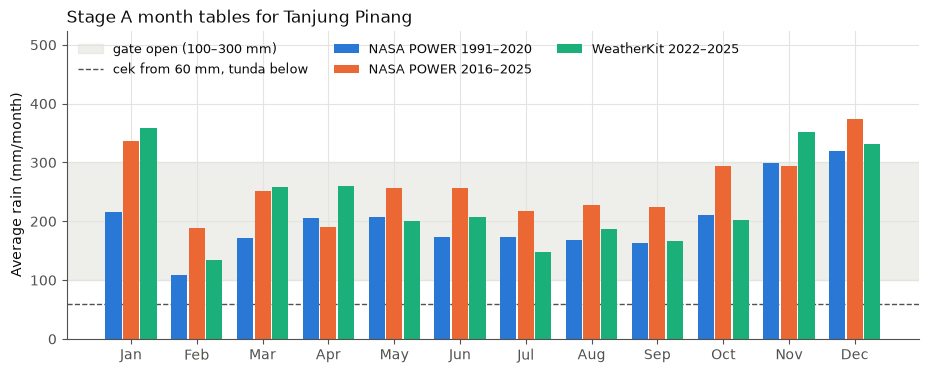

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
colors = [kw.NASA_COLOR, kw.WK_COLOR, kw.THIRD_COLOR]
width = 0.8 / len(avg.columns)
ax.axhspan(100, 300, color=kw.GRID, alpha=0.6, zorder=0, label="gate open (100–300 mm)")
for i, name in enumerate(avg.columns):
    ax.bar([x + (i - (len(avg.columns) - 1) / 2) * width for x in range(12)], avg[name], width=width * 0.92,
           color=colors[i], label=name, zorder=2)
ax.axhline(60, color=kw.MUTED, linestyle="--", linewidth=1, zorder=1, label="cek from 60 mm, tunda below")
ax.set_xticks(range(12), MONTHS)
ax.set_ylim(0, max(avg.max().max(), 300) * 1.4)
ax.set_ylabel("Average rain (mm/month)")
ax.set_title(f"Stage A month tables for {SITE_NAME}", loc="left")
ax.legend(loc="upper left", ncol=3, fontsize=9)
plt.show()

**What we found** *(run on 11 Oct 2026)*

- **NASA POWER 1991–2020:** 11 months open and only **December** closed (319 mm, tunda). November is open by 1 mm (299 mm).
- **NASA POWER 2016–2025:** 40–120 mm wetter in ten of the twelve months, which closes **January** as well (336 mm). This is the drift from notebook 1: half of these ten years fall inside it.
- **WeatherKit 2022–2025:** January, **November** and December closed.
- **No month is ever *cek*, and no month is closed for being dry.** The driest month, February, averages 108–189 mm. At Tanjung Pinang the gate only ever closes in the wet season.
- **In-band share** (1991–2020, logged only): highest in June (70%), September (60%) and August (57%); lowest in November and December (10%).

So decision 4's "10 vs 30 years" mostly measured NASA POWER's drift, not a change in climate. Only January flips (open in the 30-year table, tunda in the 10-year one). November sits on the edge: 299 mm in the 30-year table, 1 mm short of tunda, and closed in WeatherKit's.

**What Stage A can and can't do here.** A month *average* gives the same answer every year. February's in-band share of 37% means that in most years February is actually below 100 or above 200 mm, and the average hides that. Stage A at this site is close to "is it December (or January)?" The real work of L8 here is Stage B. A year-specific monthly input (BMKG's monthly outlook, iteration 2) is what would make Stage A useful.

### 4. Stage B: which days does today's forecast leave?

**Why we ask.** This is what the farmer sees: named dates, or a "check the weather" message.

Stage B takes the cached WeatherKit forecast and removes:

1. **Heavy days**, forecast over 25 mm (proposal).
2. **The day before each heavy day** (team rule, 9 Oct): fertiliser spread the day before a storm is still on the surface when it arrives.
3. **The last cached day**: there is no next-day forecast to check rule 2 against.

The days left are the *jendela tabur*. If none are left, the app says **cek hujan**. The `assert` checks the rule on a made-up forecast first: day 1 is heavy, so days 0, 1 and the last day go.

Jendela tabur: ['Sun 11 Oct', 'Mon 12 Oct', 'Tue 13 Oct', 'Wed 14 Oct', 'Thu 15 Oct', 'Fri 16 Oct', 'Sat 17 Oct', 'Sun 18 Oct', 'Mon 19 Oct']
Removed: {'heavy': [], 'day_before_heavy': [], 'last_cached': ['Tue 20 Oct']}


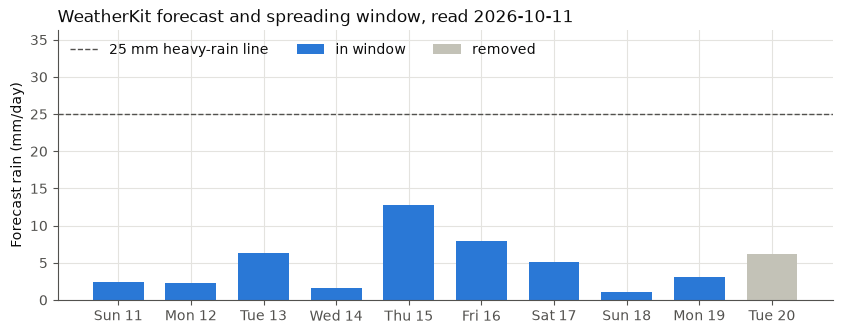

In [6]:
def stage_b_day_pick(fc, today=TODAY, heavy_mm=HEAVY_RAIN_MM):
    fc = fc[fc["date"] >= today].sort_values("date")
    dates = list(fc["date"])
    heavy = set(fc.loc[fc["rain_mm"] > heavy_mm, "date"])
    day_before = {d - timedelta(days=1) for d in heavy} & set(dates)
    last = set(dates[-1:])
    window = [d for d in dates if d not in heavy | day_before | last]
    removed = {
        "heavy": sorted(heavy),
        "day_before_heavy": sorted(day_before - heavy),
        "last_cached": sorted(last - heavy - day_before),
    }
    return window, removed


_demo = pd.DataFrame({"date": [TODAY + timedelta(days=i) for i in range(5)], "rain_mm": [2, 30, 0, 5, 1]})
_window, _ = stage_b_day_pick(_demo)
assert _window == [TODAY + timedelta(days=2), TODAY + timedelta(days=3)], _window

if forecast is not None:
    window, removed = stage_b_day_pick(forecast)
    print("Jendela tabur:" if window else "Cek hujan", [f"{d:%a %d %b}" for d in window])
    print("Removed:", {k: [f"{d:%a %d %b}" for d in v] for k, v in removed.items()})

    fc = forecast[forecast["date"] >= TODAY].sort_values("date")
    in_window = fc["date"].isin(window)
    days = pd.to_datetime(fc["date"])
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.bar(days[in_window], fc.loc[in_window, "rain_mm"], width=0.7, color=kw.NASA_COLOR, label="in window")
    ax.bar(days[~in_window], fc.loc[~in_window, "rain_mm"], width=0.7, color=kw.REMOVED, label="removed")
    ax.axhline(HEAVY_RAIN_MM, color=kw.MUTED, linestyle="--", linewidth=1, label=f"{HEAVY_RAIN_MM} mm heavy-rain line")
    ax.set_ylim(0, max(fc["rain_mm"].max(), HEAVY_RAIN_MM) * 1.45)
    ax.set_ylabel("Forecast rain (mm/day)")
    ax.set_title(f"WeatherKit forecast and spreading window, read {TODAY}", loc="left")
    ax.legend(loc="upper left", ncol=3)
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %d"))
    plt.show()
else:
    print("Skipped: no WeatherKit forecast")

**What we found** *(run on 11 Oct 2026)*

The window is **Sun 11 – Mon 19 Oct (9 days)**. No day is forecast over 25 mm (the highest is 12.8 mm on Thu 15 Oct). Only Tue 20 Oct is removed, as the last cached day.

### 5. What do the extra rules cost?

**Why we ask.** The >25 mm rule comes from the literature; the day-before rule and the last-day drop are ours. Every removed day is one the farmer can't use. The design asks to log how often the day-before rule removes dates, so L9 can test whether it helps. We don't need to wait for logs to get a first estimate.

**What we did.** Treat four years of WeatherKit history (2022–2025) as if it were a perfect 10-day forecast: for every day, take that day and the next nine, run Stage B, and count what each rule removes. Real forecasts are less certain than history, so this is the cost of the rules *if the forecast were right*. Today's archive of real forecasts is summarised too; it grows with every daily run.

1451 ten-day windows · average days offered 8.2 of 10 · windows losing ≥1 day to the day-before rule: 29% · windows with no day left (cek hujan): 0.0%


,offered,heavy,day_before_heavy,last_cached,cek hujan (%)
Jan,7.6,1.0,0.6,0.9,0.0
Feb,8.1,0.6,0.3,0.9,0.0
Mar,8.1,0.6,0.4,0.9,0.0
Apr,8.2,0.4,0.4,1.0,0.0
May,8.6,0.2,0.2,1.0,0.0
Jun,8.6,0.2,0.2,1.0,0.0
Jul,8.4,0.3,0.3,1.0,0.0
Aug,8.6,0.2,0.2,1.0,0.0
Sep,8.5,0.3,0.2,1.0,0.0
Oct,8.5,0.3,0.2,1.0,0.0


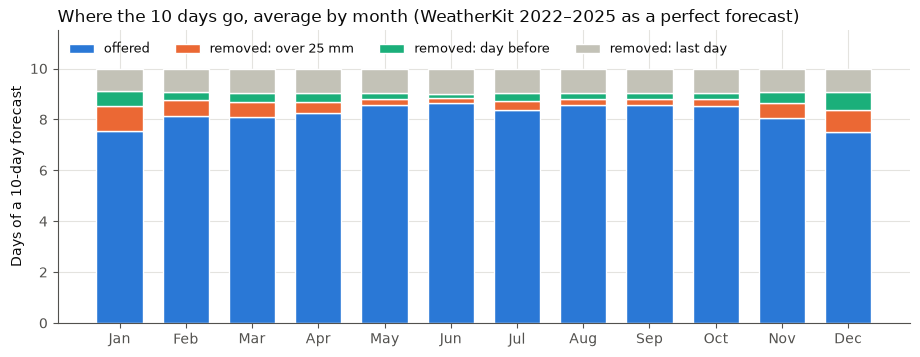

Archive of real forecasts: 1 read date(s)


,offered,heavy,day_before_heavy,last_cached
read_date,,,,
2026-10-11,9,0,0,1


In [7]:
def simulate_stage_b(rain):
    rain = rain.dropna().sort_index()
    dates, values = list(rain.index), list(rain.values)
    rows = []
    for i in range(len(dates) - 9):
        fc = pd.DataFrame({"date": dates[i:i + 10], "rain_mm": values[i:i + 10]})
        window, removed = stage_b_day_pick(fc, today=dates[i])
        rows.append({"start": dates[i], "offered": len(window), **{k: len(v) for k, v in removed.items()}})
    return pd.DataFrame(rows).set_index("start")


if wk_hist is not None:
    sim = simulate_stage_b(wk_hist)
    by_month = sim.groupby(pd.to_datetime(sim.index).month).mean()
    by_month["cek hujan (%)"] = (sim["offered"] == 0).groupby(pd.to_datetime(sim.index).month).mean() * 100
    by_month.index = MONTHS
    print(f"{len(sim)} ten-day windows · average days offered {sim['offered'].mean():.1f} of 10 · "
          f"windows losing ≥1 day to the day-before rule: {(sim['day_before_heavy'] > 0).mean():.0%} · "
          f"windows with no day left (cek hujan): {(sim['offered'] == 0).mean():.1%}")
    display(by_month.round(1))

    parts = [("offered", kw.NASA_COLOR, "offered"), ("heavy", kw.WK_COLOR, "removed: over 25 mm"),
             ("day_before_heavy", kw.THIRD_COLOR, "removed: day before"), ("last_cached", kw.REMOVED, "removed: last day")]
    fig, ax = plt.subplots(figsize=(11, 3.8))
    bottom = pd.Series(0.0, index=by_month.index)
    for col, color, label in parts:
        ax.bar(range(12), by_month[col], bottom=bottom, color=color, width=0.7, label=label, edgecolor="white", linewidth=1)
        bottom += by_month[col]
    ax.set_xticks(range(12), MONTHS)
    ax.set_ylim(0, 11.5)
    ax.set_ylabel("Days of a 10-day forecast")
    ax.set_title("Where the 10 days go, average by month (WeatherKit 2022–2025 as a perfect forecast)", loc="left")
    ax.legend(loc="upper left", ncol=4, fontsize=9)
    plt.show()
else:
    print("Skipped the simulation: no WeatherKit credentials")

snapshots = kw.load_forecast_snapshots()
if len(snapshots):
    latest = snapshots.drop_duplicates(["read_date", "date"], keep="last")
    archive = pd.DataFrame([
        {"read_date": read, "offered": len(w), **{k: len(v) for k, v in r.items()}}
        for read, g in latest.groupby("read_date")
        for w, r in [stage_b_day_pick(g, today=read)]
    ]).set_index("read_date")
    print(f"Archive of real forecasts: {len(archive)} read date(s)")
    display(archive)

**What we found** *(run on 11 Oct 2026; WeatherKit 2022–2025 used as a perfect forecast)*

- Across **1,451 ten-day windows**, Stage B offers **8.2 of 10 days** on average, and **no window ever ends with zero days** (no *cek hujan*).
- **The last-day drop costs the most:** about one day in every window. It is structural, not about rain.
- **The >25 mm rule** removes 0.2–0.3 days per window from May to October and up to 1.0 day in January.
- **The day-before rule** removes 0.2–0.7 days per window, and at least one day in **29%** of windows. It costs most in December and January, when Stage A usually closes the month anyway.
- **The archive of real forecasts** has one read date so far (today: 9 offered, nothing removed except the last day).

So the day-before rule is cheap: about a third of a day per window. That makes it easy to keep while L9 tests whether it helps. Real forecasts carry false alarms that history doesn't, so actual removals will be somewhat higher. The archive will show by how much.

### 6. Do the sources agree on heavy days?

**Why we ask.** Stage B removes days over 25 mm, so what matters is whether a heavy day is seen at all. Two independent models agreeing on a heavy day make it more believable; one seeing it and the other not shows how uncertain heavy-day detection is.

**What we did.** NASA POWER (trusted months only, using the check from notebook 1) against WeatherKit history, day by day since Aug 2021.

In [8]:
this_year, _, _ = kw.fetch_nasa_power(min(date(TODAY.year, 1, 1), TODAY - timedelta(days=120)), TODAY)
nasa_all = pd.concat([nasa_hist, this_year["PRECTOTCORR"].dropna()])
nasa_all = nasa_all[~nasa_all.index.duplicated(keep="last")].sort_index()

both = None
if WK_READY:
    wk_all = kw.fetch_weatherkit_history(date(2021, 8, 1), nasa_all.index.max())["rain_mm"]
    check = kw.suspect_months(nasa_all[nasa_all.index >= date(2021, 8, 1)], kw.monthly_normals(nasa_all), wk_all)
    nasa_ok = kw.drop_months(nasa_all, check.index[check["suspect"]])
    both = pd.concat({"NASA POWER": nasa_ok, "WeatherKit": wk_all}, axis=1).dropna()

    hits, nasa_only, wk_only = kw.agreement(both["NASA POWER"], both["WeatherKit"], HEAVY_RAIN_MM)
    print(f"{len(both)} days compared ({both.index.min()} to {both.index.max()}), suspect NASA POWER months left out")
    print(f"Days over {HEAVY_RAIN_MM} mm — both: {hits} · only NASA POWER: {nasa_only} · only WeatherKit: {wk_only}")

    heavy = both > HEAVY_RAIN_MM
    per_year = heavy.groupby(pd.to_datetime(heavy.index).year).sum()
    per_year["both"] = (heavy["NASA POWER"] & heavy["WeatherKit"]).groupby(pd.to_datetime(heavy.index).year).sum()
    per_year["days compared"] = heavy.groupby(pd.to_datetime(heavy.index).year).size()
    display(per_year)

    print("Largest disagreements on heavy days:")
    disagree = both[heavy["NASA POWER"] != heavy["WeatherKit"]]
    display(disagree.assign(gap=(disagree["NASA POWER"] - disagree["WeatherKit"]).abs()).nlargest(8, "gap").round(1))
else:
    print("Skipped: no WeatherKit credentials")

1560 days compared (2021-08-01 to 2026-10-08), suspect NASA POWER months left out
Days over 25 mm — both: 26 · only NASA POWER: 111 · only WeatherKit: 45


,NASA POWER,WeatherKit,both,days compared
2021,10,4,1,153
2022,19,17,1,365
2023,43,23,12,364
2024,20,14,5,306
2025,45,12,7,334
2026,0,1,0,38


Largest disagreements on heavy days:


,NASA POWER,WeatherKit,gap
2023-08-12,176.9,3.4,173.5
2025-06-10,89.8,7.6,82.2
2025-01-27,84.6,14.7,69.9
2025-06-22,65.3,0.3,65.0
2025-07-31,64.2,1.0,63.3
2024-10-30,63.1,0.8,62.3
2025-10-06,63.2,1.3,61.9
2025-10-25,62.4,4.5,57.8


**What we found** *(run on 11 Oct 2026; 1,560 days from Aug 2021 to 8 Oct 2026, suspect NASA POWER months left out)*

- **The sources rarely agree on heavy days.** NASA POWER has 137 days over 25 mm, WeatherKit 71, and they share only **26**. Only 37% of WeatherKit's heavy days are heavy in NASA POWER too.
- **NASA POWER's heavy days pile up in its drift years:** 43 in 2023 and 45 in 2025, against 19–20 in 2022 and 2024. The largest disagreements are all NASA POWER heavy and WeatherKit dry. The biggest, 12 Aug 2023, is 176.9 vs 3.4 mm.
- A 55 × 70 km average should *smooth out* heavy days, not multiply them. That NASA POWER has twice as many as WeatherKit is one more sign its recent data runs wet.

Stage B runs on WeatherKit, so NASA POWER can't confirm or deny WeatherKit's heavy days. Its numbers are least reliable exactly where L8 needs them. Only measured rain can settle which heavy days were real (step 7).

### 7. How good is the forecast 1–3 days ahead?

**Why we ask.** Everything above uses history. Stage B acts on *forecasts*, and a forecast for 3 days ahead is less certain than one for tomorrow. The question that decides whether L8 works: of the days that really got over 25 mm, how many did the forecast flag 1–3 days before?

**What we did.** Every daily run saves the forecast to `data/raw/`. Once BMKG data (`data/bmkg.xlsx`) or gauge readings (`data/gauge.csv`) cover the same days, this cell scores each lead time against them. The loader and the date-shift check are explained in notebook 1, step 6.

| Score | Meaning for L8 |
| --- | --- |
| `heavy_hits` | Reference over 25 mm, and the forecast said so |
| `heavy_misses` | Reference over 25 mm, the forecast didn't see it: **fertiliser spread into a storm**, the costly error |
| `false_alarms` | Forecast over 25 mm, reference wasn't: a good spreading day lost, a cheaper error |
| `bias_mm`, `mae_mm` | Mean and typical size of the daily error |

In [9]:
refs = kw.load_references()
snapshots = kw.load_forecast_snapshots()
leads = sorted(int(x) for x in snapshots["lead_days"].unique()) if len(snapshots) else []
print(f"Forecast archive: {snapshots['read_date'].nunique() if len(snapshots) else 0} read date(s), lead times {leads}")

if refs:
    sources = {}
    for lead, group in snapshots.groupby("lead_days") if len(snapshots) else []:
        sources[f"WeatherKit forecast, lead {lead} d"] = group.drop_duplicates("date", keep="last").set_index("date")["rain_mm"]
    if both is not None:
        sources["WeatherKit history"] = both["WeatherKit"]
        sources["NASA POWER"] = both["NASA POWER"]
    display(kw.score_table(refs, sources))
else:
    print(f"No reference data yet: add a BMKG export as {kw.BMKG_FILES[0].relative_to(kw.HERE)} and/or {kw.GAUGE_CSV.relative_to(kw.HERE)}")

Forecast archive: 1 read date(s), lead times [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
No reference data yet: add a BMKG export as data/bmkg.xlsx and/or data/gauge.csv


**What we found** *(run on 11 Oct 2026)*

The archive has **one read date** (today), with lead times 0–9 days, and there is no measured rain yet. Nothing can be scored.

What it needs:
- Run this notebook (or just the forecast fetch) **every day**.
- Add **BMKG data** for the same weeks.

With a month of overlap, the 1-, 2- and 3-day leads each get about 30 days to score. Heavy days are what matter, and there are only a few a month, so a few months through the north-east monsoon will be needed before the hit/miss counts mean much.

### 8. Putting it together: the L8 decision, end to end

Stage A and Stage B combined into the four states the recipe can show:

| State | When | Recipe shows |
| --- | --- | --- |
| **Tunda** | This month's average is under 60 or over 300 mm | Wait; no dates |
| **Cek** | This month's average is 60–100 mm | Check soil and weather before spreading |
| **Jendela tabur** | Gate open and at least one forecast day passes Stage B | Named dates |
| **Cek hujan** | Gate open but no day left (or no forecast cached) | Check the weather before spreading |

The month table is the 1991–2020 one (step 3). The *proposed* rule for a window that runs into next month is applied too: dates in a month whose own gate isn't open are dropped.

In [10]:
GATE_TABLE = tables["NASA POWER 1991–2020"]


def l8_decision(fc, table=GATE_TABLE, today=TODAY):
    gate = {month: month_gate(a) for month, a in table["avg_mm"].items()}
    result = {"date": today, "month_avg_mm": round(table.loc[today.month, "avg_mm"]), "month_gate": gate[today.month]}
    if gate[today.month] == "tunda":
        return result | {"state": "Tunda", "dates": []}
    if gate[today.month] == "cek":
        return result | {"state": "Cek", "dates": []}
    if fc is None:
        return result | {"state": "Cek hujan", "dates": []}
    window, removed = stage_b_day_pick(fc, today)
    window = [d for d in window if gate[d.month] == "open"]  # proposed: the window stops at a closed month
    return result | {"state": "Jendela tabur" if window else "Cek hujan", "dates": window, "removed": removed}


decision = l8_decision(forecast)
print(f"{SITE_NAME}, {TODAY:%d %b %Y}: {decision['state']}")
print(f"Month gate: {decision['month_gate']} ({TODAY:%B} average {decision['month_avg_mm']} mm, NASA POWER 1991–2020)")
if decision["dates"]:
    print("Dates:", ", ".join(f"{d:%a %d %b}" for d in decision["dates"]))

Tanjung Pinang, 11 Oct 2026: Jendela tabur
Month gate: open (October average 210 mm, NASA POWER 1991–2020)
Dates: Sun 11 Oct, Mon 12 Oct, Tue 13 Oct, Wed 14 Oct, Thu 15 Oct, Fri 16 Oct, Sat 17 Oct, Sun 18 Oct, Mon 19 Oct


### Where this leaves us *(run on 11 Oct 2026)*

**Today's L8 output for the Tanjung Pinang plot: Jendela tabur, Sun 11 – Mon 19 Oct (9 dates).** October averages 210 mm (NASA POWER 1991–2020), so the gate is open, and no forecast day is over 25 mm.

| | Status |
| --- | --- |
| WeatherKit's daily forecast exists here; next-hour and alerts don't | Verified |
| BMKG's API reaches only about two days ahead | Verified |
| Stage B logic | Verified (assert on a made-up forecast) |
| Stage A at this site: open all year except December (1991–2020 table) | Computed; depends on which table (step 3) |
| Cost of the day-before rule: about 0.3 days per window | Estimated from history as a perfect forecast |
| NASA POWER and WeatherKit agree on heavy days | **No:** only 26 shared of 182 heavy days in either |
| Does the forecast catch heavy days 1–3 days ahead? | **Open:** needs the archive and BMKG data (step 7) |
| Which month the Pradiko rule means; a source for the day-before rule | **Open** |

**Recommendations**
- **Stage A:** use the **1991–2020** NASA POWER table (the WMO normal period, before the drift), cross-checked against WeatherKit, until NASA POWER's recent years are explained. This settles decision 4 for now.
- **Validation effort:** spend it on **Stage B**. At this site Stage A rarely closes, so L8's value depends on the forecast catching heavy days. Daily forecast archiving plus BMKG data is the single most useful next step.
- **The last-day drop costs more than the day-before rule.** If short windows become a complaint, a longer forecast (Open-Meteo's 16 days, paid) would remove most of that cost.

### Open questions

- **Does the forecast catch heavy days 1–3 days ahead?** (Step 7.) Run this notebook daily and add BMKG data; after 4–8 weeks of the north-east monsoon there should be enough heavy days to score.
- **Which month does Pradiko & Koedadiri (2015) mean** in the rainfall rule: the month of spreading, or the month after? Read the Warta PPKS article.
- **Is there a source for the day-before rule?** PPKS guidance on dry days needed after spreading. Step 5 shows what it costs; L9 can test what it saves.
- **How do farmers and the KUD decide today?** The field interview decides whether Tunda/Cek/Jendela matches how spreading is actually planned.
- **Is 10 days enough?** If the window often shrinks to a few days, a 16-day forecast (Open-Meteo, paid) or BMKG's monthly outlook could help.

---
**Attribution.** Weather data: Apple Weather — [other data sources](https://developer.apple.com/weatherkit/data-source-attribution/); any recipe showing Apple weather data carries the Apple Weather mark and this link. Forecast for the kelurahan: BMKG (Badan Meteorologi, Klimatologi, dan Geofisika). These data were obtained from the NASA Langley Research Center (LaRC) POWER Project funded through the NASA Earth Science/Applied Science Program. Raw API responses stay in `data/raw/` (git-ignored); Apple's terms for storing WeatherKit data have not been checked yet.